# CIFAR-10 선형 분류기 (무작위 가중치)

학습 없이 무작위로 초기화한 가중치 `W`와 0 편향 `b`로 선형 분류기 `f(x) = Wx + b`가
클래스 점수를 계산하고 예측하는 과정을 확인한다. 이어서 다중 클래스 SVM hinge loss,
Softmax, 분류 사례, 가중치 시각화를 차례로 다룬다.

## 0. 데이터 불러오기 및 전처리

In [1]:
import pickle, os
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
DATA_DIR = 'cifar-10-batches-py'   # 압축을 푼 CIFAR-10 폴더 경로
os.makedirs('results', exist_ok=True)

def unpickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='bytes')

meta = unpickle(os.path.join(DATA_DIR, 'batches.meta'))
CLASSES = [c.decode() for c in meta[b'label_names']]

train = unpickle(os.path.join(DATA_DIR, 'data_batch_1'))
test = unpickle(os.path.join(DATA_DIR, 'test_batch'))
X_train = train[b'data'].astype(np.float64)          # (10000, 3072)
X_test_raw = test[b'data']                           # (10000, 3072), uint8
y_test = np.array(test[b'labels'])

# 전처리: [0,1] 스케일링 후 학습 데이터 평균 이미지를 빼서 0 중심화
mean_image = X_train.mean(axis=0) / 255.0
X_test = X_test_raw.astype(np.float64) / 255.0 - mean_image

def to_img(row):
    # CIFAR-10 행 벡터(R 1024, G 1024, B 1024) -> (32, 32, 3)
    return row.reshape(3, 32, 32).transpose(1, 2, 0)

print('classes:', CLASSES)
print('X_test shape:', X_test.shape)

classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
X_test shape: (10000, 3072)


## 1. 가중치 초기화 (W: 작은 무작위 값, b: 0, 시드 고정)

In [2]:
SEED = 42
rng = np.random.default_rng(SEED)

D = 32 * 32 * 3   # 3072
K = 10            # 클래스 수
W = 0.01 * rng.standard_normal((K, D))   # (10, 3072)
b = np.zeros(K)                          # (10,)

print('W shape:', W.shape, '| mean = %.5f, std = %.5f' % (W.mean(), W.std()))
print('b:', b)

W shape: (10, 3072) | mean = 0.00009, std = 0.01004
b: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 2. 선형 분류기 `f(x) = Wx + b` 와 예측

In [3]:
def linear_scores(X, W, b):
    # X: (N, D) -> scores: (N, K). 각 행이 f(x) = Wx + b
    return X @ W.T + b

N_EX = 20
idx = np.arange(N_EX)            # 테스트 셋 앞 20장을 예시로 사용
X_ex, y_ex = X_test[idx], y_test[idx]

scores = linear_scores(X_ex, W, b)       # (20, 10)
pred = scores.argmax(axis=1)

header = f"{'#':>2} {'true':>10} {'pred':>10} | " + ' '.join(f'{c[:5]:>6}' for c in CLASSES)
print(header); print('-' * len(header))
for i in range(N_EX):
    print(f"{i:>2} {CLASSES[y_ex[i]]:>10} {CLASSES[pred[i]]:>10} | "
          + ' '.join(f'{s:6.3f}' for s in scores[i]))

 #       true       pred |  airpl  autom   bird    cat   deer    dog   frog  horse   ship  truck
------------------------------------------------------------------------------------------------
 0        cat automobile |  0.184  0.220 -0.098  0.154  0.063  0.024 -0.025  0.028 -0.086  0.131
 1       ship       ship | -0.072  0.147 -0.137 -0.217  0.159  0.195  0.080 -0.069  0.336  0.030
 2       ship automobile | -0.059  0.333 -0.108 -0.202 -0.006  0.134 -0.176  0.024  0.082 -0.107
 3   airplane        dog | -0.053  0.266 -0.249  0.029  0.130  0.294  0.217  0.144  0.117  0.162
 4       frog        cat | -0.123 -0.090 -0.041  0.110 -0.110 -0.135  0.085 -0.067  0.080  0.057
 5       frog       bird |  0.133  0.011  0.173  0.005  0.063 -0.038  0.023 -0.097 -0.129  0.076
 6 automobile      truck |  0.013 -0.214  0.040  0.160 -0.188 -0.188 -0.258 -0.205 -0.172  0.166
 7       frog        cat | -0.017 -0.030 -0.077  0.279  0.005 -0.105  0.004  0.056 -0.211  0.169
 8        cat       frog | -0.

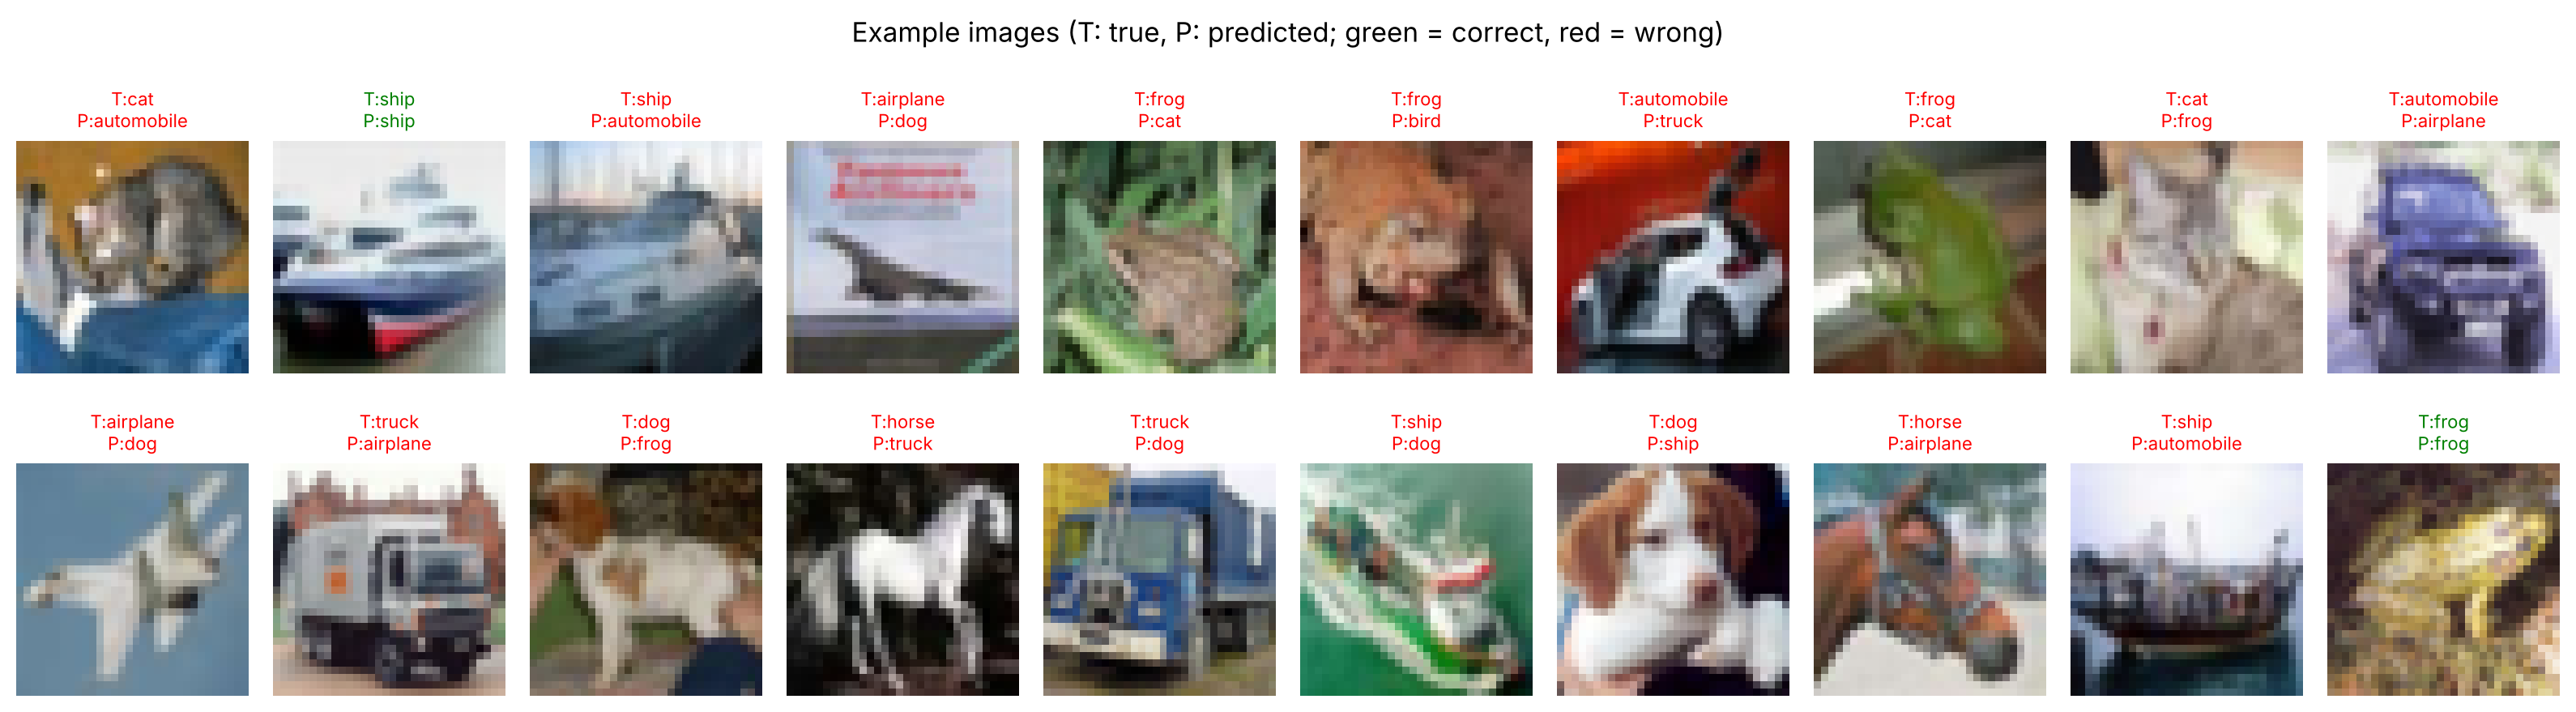

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(16, 4.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test_raw[i].reshape(3, 32, 32).transpose(1, 2, 0))
    ok = pred[i] == y_ex[i]
    ax.set_title(f'T:{CLASSES[y_ex[i]]}\nP:{CLASSES[pred[i]]}', fontsize=8,
                 color='green' if ok else 'red')
    ax.axis('off')
plt.suptitle('Example images (T: true, P: predicted; green = correct, red = wrong)')
plt.tight_layout(); plt.savefig('results/examples_predictions.png', dpi=120); plt.show()

## 3. 다중 클래스 SVM hinge loss

$$L_i = \sum_{j \neq y_i} \max(0,\ s_j - s_{y_i} + \Delta), \quad \Delta = 1$$

In [5]:
def svm_loss(scores, y, delta=1.0):
    N = scores.shape[0]
    correct = scores[np.arange(N), y][:, None]          # s_{y_i}
    margins = np.maximum(0, scores - correct + delta)   # max(0, s_j - s_yi + 1)
    margins[np.arange(N), y] = 0                        # j = y_i 항 제외
    per_example = margins.sum(axis=1)
    return per_example.mean(), per_example

svm_mean, svm_each = svm_loss(scores, y_ex)
for i in range(N_EX):
    print(f'#{i:>2} ({CLASSES[y_ex[i]]:>10}) L_i = {svm_each[i]:.4f}')
print(f'\n평균 SVM loss = {svm_mean:.4f}  (참고: 모든 점수가 ≈0이면 K-1 = {K-1})')

# 0 (       cat) L_i = 8.0561
# 1 (      ship) L_i = 6.0878
# 2 (      ship) L_i = 8.0963
# 3 (  airplane) L_i = 10.5872
# 4 (      frog) L_i = 7.9186
# 5 (      frog) L_i = 8.9906
# 6 (automobile) L_i = 10.2887
# 7 (      frog) L_i = 9.0342
# 8 (       cat) L_i = 9.8045
# 9 (automobile) L_i = 8.9563
#10 (  airplane) L_i = 9.3550
#11 (     truck) L_i = 12.4132
#12 (       dog) L_i = 10.5119
#13 (     horse) L_i = 11.1303
#14 (     truck) L_i = 9.1452
#15 (      ship) L_i = 8.2424
#16 (       dog) L_i = 9.3532
#17 (     horse) L_i = 10.1258
#18 (      ship) L_i = 9.0337
#19 (      frog) L_i = 6.1619

평균 SVM loss = 9.1646  (참고: 모든 점수가 ≈0이면 K-1 = 9)


## 4. Softmax: 점수 → 확률

In [6]:
def softmax(scores):
    shifted = scores - scores.max(axis=1, keepdims=True)   # 수치 안정성
    e = np.exp(shifted)
    return e / e.sum(axis=1, keepdims=True)

probs = softmax(scores)

for i in range(3):   # 앞 3장은 점수와 확률을 나란히 비교
    print(f'[Image #{i}] true = {CLASSES[y_ex[i]]}')
    print(f"{'class':>10} {'score':>8} {'prob':>8}")
    for k in range(K):
        print(f'{CLASSES[k]:>10} {scores[i, k]:8.4f} {probs[i, k]:8.4f}')
    print()

sums = probs.sum(axis=1)
print('이미지별 확률 합:', sums)
print('모두 1인가?', np.allclose(sums, 1.0))
print('argmax(score) == argmax(prob)?', np.array_equal(scores.argmax(1), probs.argmax(1)))

# 참고: Softmax(cross-entropy) loss
ce = -np.log(probs[np.arange(N_EX), y_ex])
print(f'\n평균 cross-entropy loss = {ce.mean():.4f}  (참고: -log(1/10) = {np.log(10):.4f})')

[Image #0] true = cat
     class    score     prob
  airplane   0.1839   0.1126
automobile   0.2200   0.1168
      bird  -0.0982   0.0849
       cat   0.1538   0.1093
      deer   0.0629   0.0998
       dog   0.0242   0.0960
      frog  -0.0253   0.0914
     horse   0.0284   0.0964
      ship  -0.0865   0.0859
     truck   0.1313   0.1069

[Image #1] true = ship
     class    score     prob
  airplane  -0.0716   0.0878
automobile   0.1466   0.1092
      bird  -0.1374   0.0822
       cat  -0.2171   0.0759
      deer   0.1587   0.1106
       dog   0.1947   0.1146
      frog   0.0802   0.1022
     horse  -0.0694   0.0880
      ship   0.3364   0.1321
     truck   0.0303   0.0972

[Image #2] true = ship
     class    score     prob
  airplane  -0.0590   0.0939
automobile   0.3334   0.1390
      bird  -0.1078   0.0894
       cat  -0.2024   0.0814
      deer  -0.0057   0.0991
       dog   0.1343   0.1139
      frog  -0.1760   0.0835
     horse   0.0243   0.1021
      ship   0.0820   0.1081
  

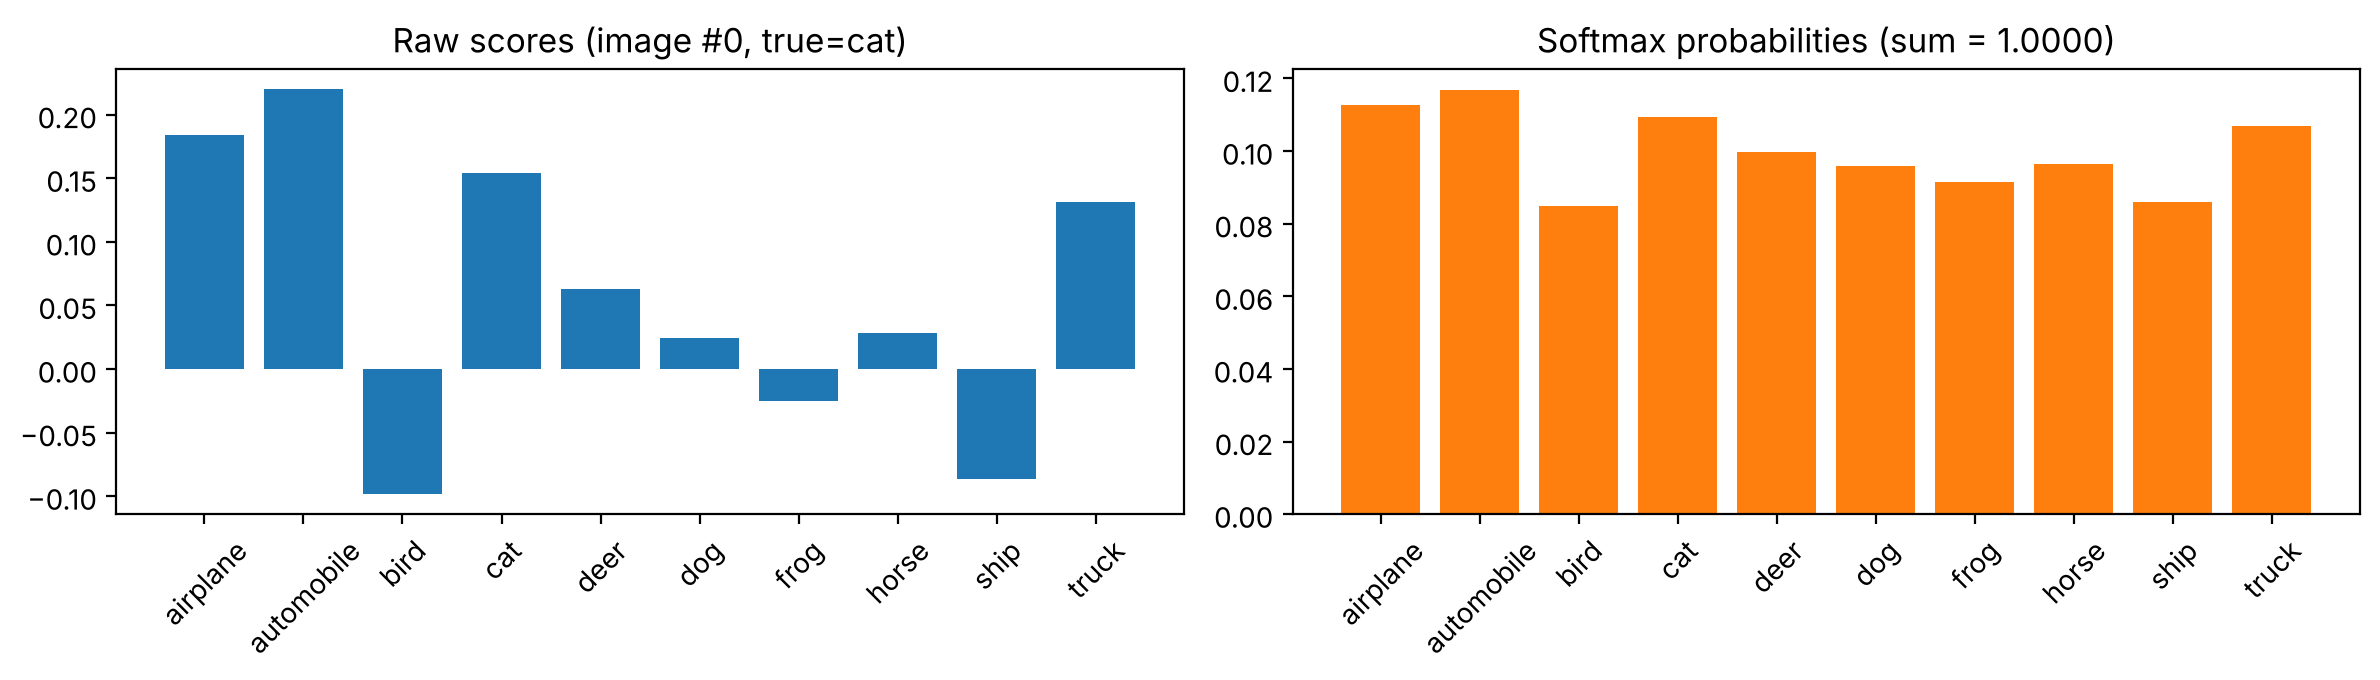

In [7]:
i = 0
x = np.arange(K)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(x, scores[i]); ax[0].set_title(f'Raw scores (image #{i}, true={CLASSES[y_ex[i]]})')
ax[1].bar(x, probs[i], color='tab:orange'); ax[1].set_title('Softmax probabilities (sum = %.4f)' % probs[i].sum())
for a in ax:
    a.set_xticks(x); a.set_xticklabels(CLASSES, rotation=45)
plt.tight_layout(); plt.savefig('results/scores_vs_softmax.png', dpi=120); plt.show()

## 5. 올바르게 분류한 사례 / 잘못 분류한 사례

예시 20장 중 정답 2장, 오답 18장


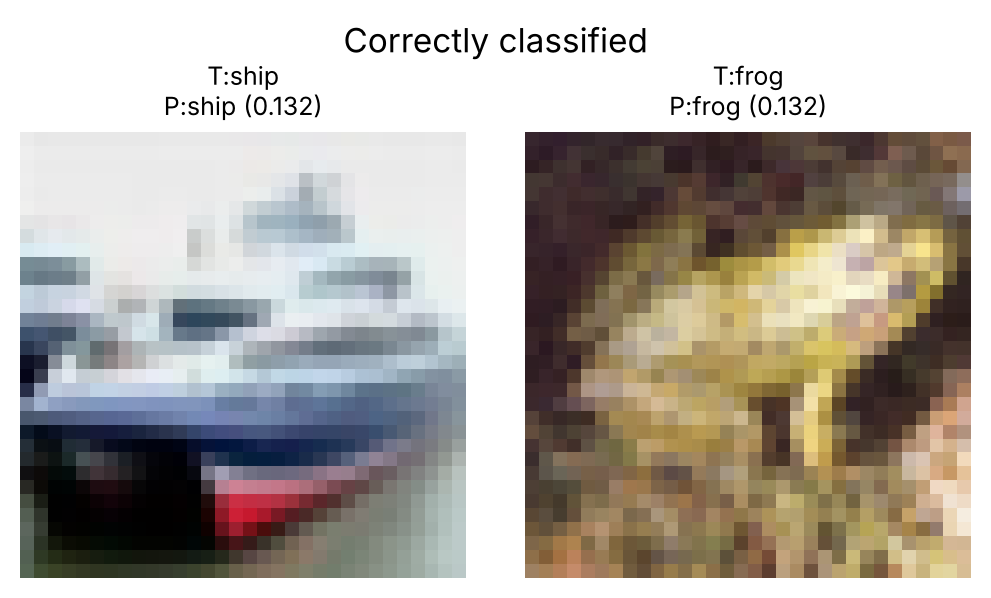

  #1: true=ship, pred=ship, p(pred)=0.132, p(true)=0.132
  #19: true=frog, pred=frog, p(pred)=0.132, p(true)=0.132


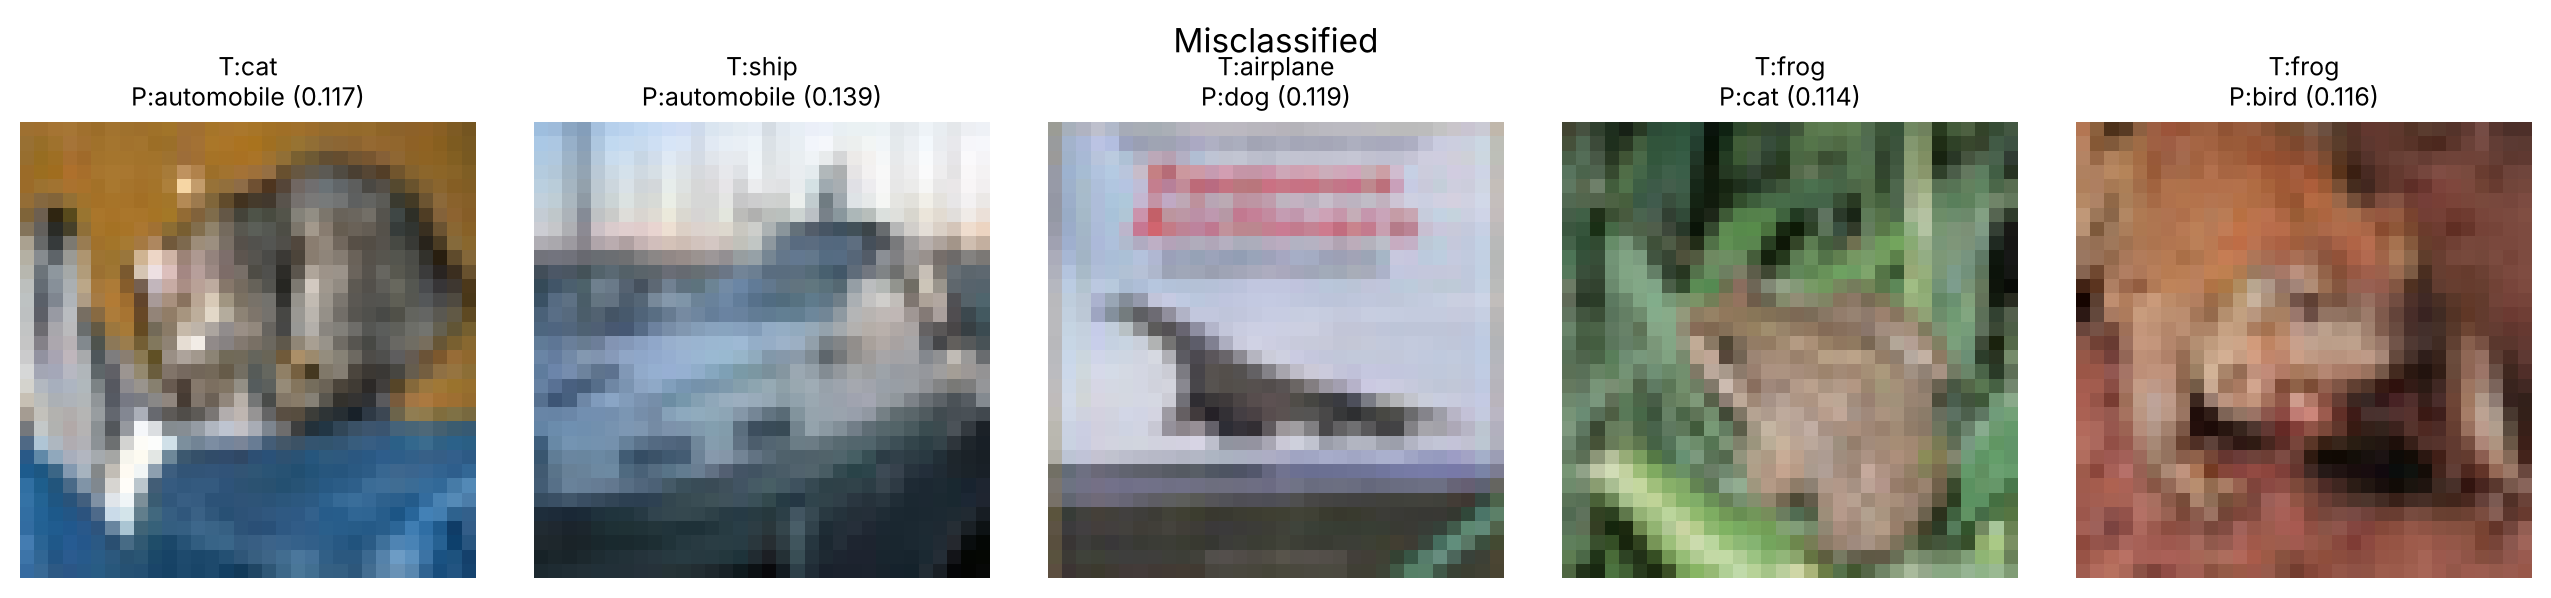

  #0: true=cat, pred=automobile, p(pred)=0.117, p(true)=0.109
  #2: true=ship, pred=automobile, p(pred)=0.139, p(true)=0.108
  #3: true=airplane, pred=dog, p(pred)=0.119, p(true)=0.084
  #4: true=frog, pred=cat, p(pred)=0.114, p(true)=0.111
  #5: true=frog, pred=bird, p(pred)=0.116, p(true)=0.100


In [8]:
correct_idx = np.where(pred == y_ex)[0]
wrong_idx = np.where(pred != y_ex)[0]
print(f'예시 {N_EX}장 중 정답 {len(correct_idx)}장, 오답 {len(wrong_idx)}장')

def show_cases(ids, title, fname, n=5):
    ids = ids[:n]
    if len(ids) == 0:
        print(f'{title}: 해당 사례 없음'); return
    fig, axes = plt.subplots(1, len(ids), figsize=(2.6 * len(ids), 3), squeeze=False)
    for ax, i in zip(axes[0], ids):
        ax.imshow(X_test_raw[i].reshape(3, 32, 32).transpose(1, 2, 0)); ax.axis('off')
        ax.set_title(f'T:{CLASSES[y_ex[i]]}\nP:{CLASSES[pred[i]]} ({probs[i, pred[i]]:.3f})', fontsize=9)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()
    for i in ids:
        print(f'  #{i}: true={CLASSES[y_ex[i]]}, pred={CLASSES[pred[i]]}, '
              f'p(pred)={probs[i, pred[i]]:.3f}, p(true)={probs[i, y_ex[i]]:.3f}')

show_cases(correct_idx, 'Correctly classified', 'results/correct_cases.png')
show_cases(wrong_idx, 'Misclassified', 'results/wrong_cases.png')

**설명**: 가중치가 무작위이므로 점수는 이미지 내용과 무관한 무작위 투영값이다.
정답이 나온 사례도 모델이 해당 클래스를 "인식"한 것이 아니라 우연히 정답 클래스의 점수가 가장 컸을 뿐이며,
예측 확률도 0.1 근처로 확신이 거의 없다. 기대 정확도는 1/10 = 10% 수준이다.

## 6. 클래스별 가중치 시각화 (32 × 32 × 3)

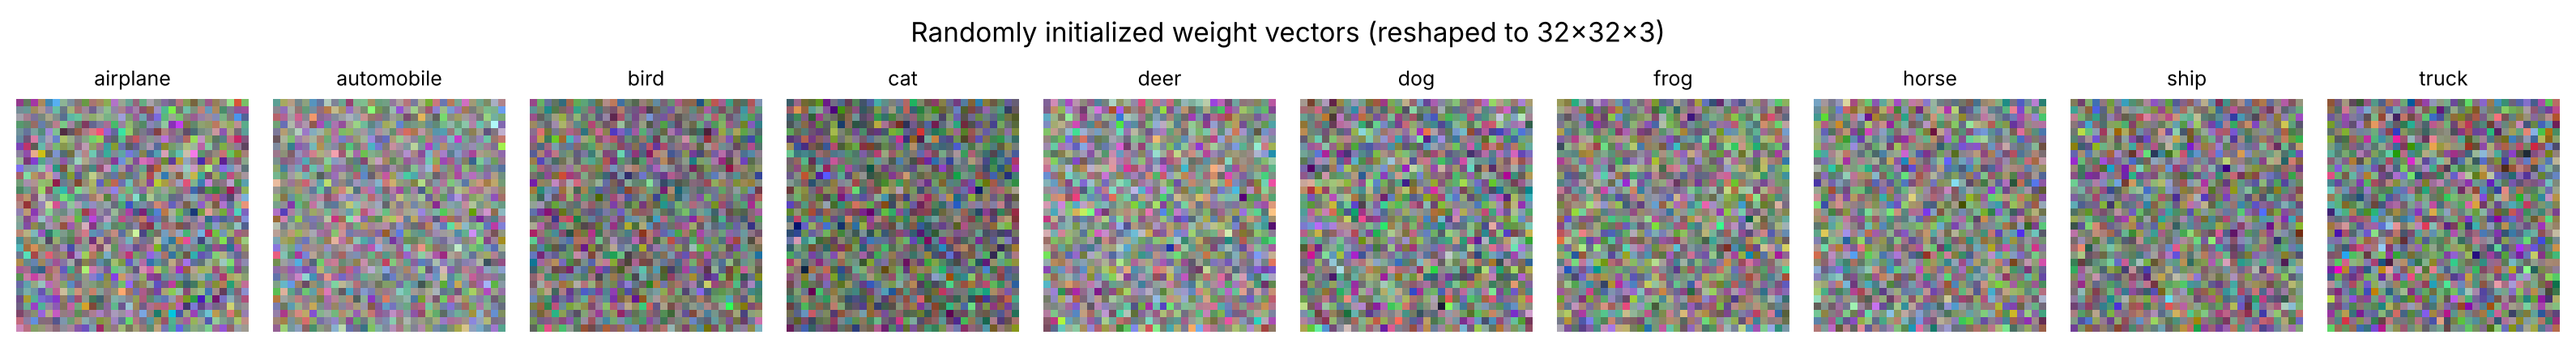

In [9]:
fig, axes = plt.subplots(1, K, figsize=(16, 2.2))
for k, ax in enumerate(axes):
    w_img = to_img(W[k])
    w_img = (w_img - w_img.min()) / (w_img.max() - w_img.min())   # [0,1]로 정규화
    ax.imshow(w_img); ax.set_title(CLASSES[k], fontsize=9); ax.axis('off')
plt.suptitle('Randomly initialized weight vectors (reshaped to 32x32x3)')
plt.tight_layout(); plt.savefig('results/weights_visualization.png', dpi=120); plt.show()

**설명**: 각 행 `W[k]`는 클래스 k의 "템플릿"이며, 점수 `W[k]·x`는 이미지와 템플릿의 내적(유사도)이다.
학습을 하면 손실을 줄이는 방향으로 경사하강법이 W를 갱신하면서 각 템플릿이 해당 클래스 이미지들의 평균적인 색·형태
(예: airplane/ship은 파란 배경, horse는 갈색 몸통)를 닮아 간다.
그러나 여기의 W는 데이터를 한 번도 보지 않고 정규분포에서 독립적으로 뽑은 값이라 픽셀 사이에 공간적 상관관계가 없고,
어떤 클래스와도 관련이 없다. 따라서 10개 이미지 모두 구분되지 않는 컬러 노이즈로 보인다.